In [1]:
import pandas as pd
df=pd.read_csv('bank-additional-full.csv',sep=';')
print(df.shape)
df.head()

(41188, 21)


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [2]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

## EXPLORATORY DATA ANALYSIS

In [3]:
from IPython.display import display
df.info()    
display(df.describe())
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
print(df['y'].value_counts(normalize=True))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  object 
 2   marital         41188 non-null  object 
 3   education       41188 non-null  object 
 4   default         41188 non-null  object 
 5   housing         41188 non-null  object 
 6   loan            41188 non-null  object 
 7   contact         41188 non-null  object 
 8   month           41188 non-null  object 
 9   day_of_week     41188 non-null  object 
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  object 
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   41188 non-null 

,age,duration,campaign,pdays,previous,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed
count,41188.00000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000
mean,40.02406,258.285010,2.567593,962.475454,0.172963,0.081886,93.575664,-40.502600,3.621291,5167.035911
std,10.42125,259.279249,2.770014,186.910907,0.494901,1.570960,0.578840,4.628198,1.734447,72.251528
min,17.00000,0.000000,1.000000,0.000000,0.000000,-3.400000,92.201000,-50.800000,0.634000,4963.600000
25%,32.00000,102.000000,1.000000,999.000000,0.000000,-1.800000,93.075000,-42.700000,1.344000,5099.100000
50%,38.00000,180.000000,2.000000,999.000000,0.000000,1.100000,93.749000,-41.800000,4.857000,5191.000000
75%,47.00000,319.000000,3.000000,999.000000,0.000000,1.400000,93.994000,-36.400000,4.961000,5228.100000
max,98.00000,4918.000000,56.000000,999.000000,7.000000,1.400000,94.767000,-26.900000,5.045000,5228.100000


Missing values: 0
Duplicate rows: 12
y
no     0.887346
yes    0.112654
Name: proportion, dtype: float64


In [4]:
df = df.drop_duplicates()

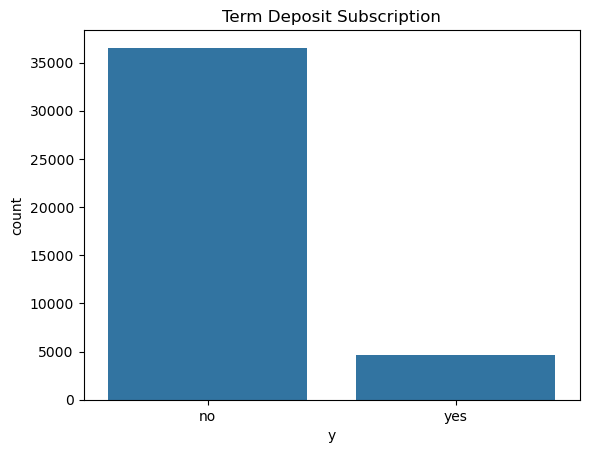

In [5]:
sns.countplot(x='y', data=df)
plt.title('Term Deposit Subscription')
plt.show()

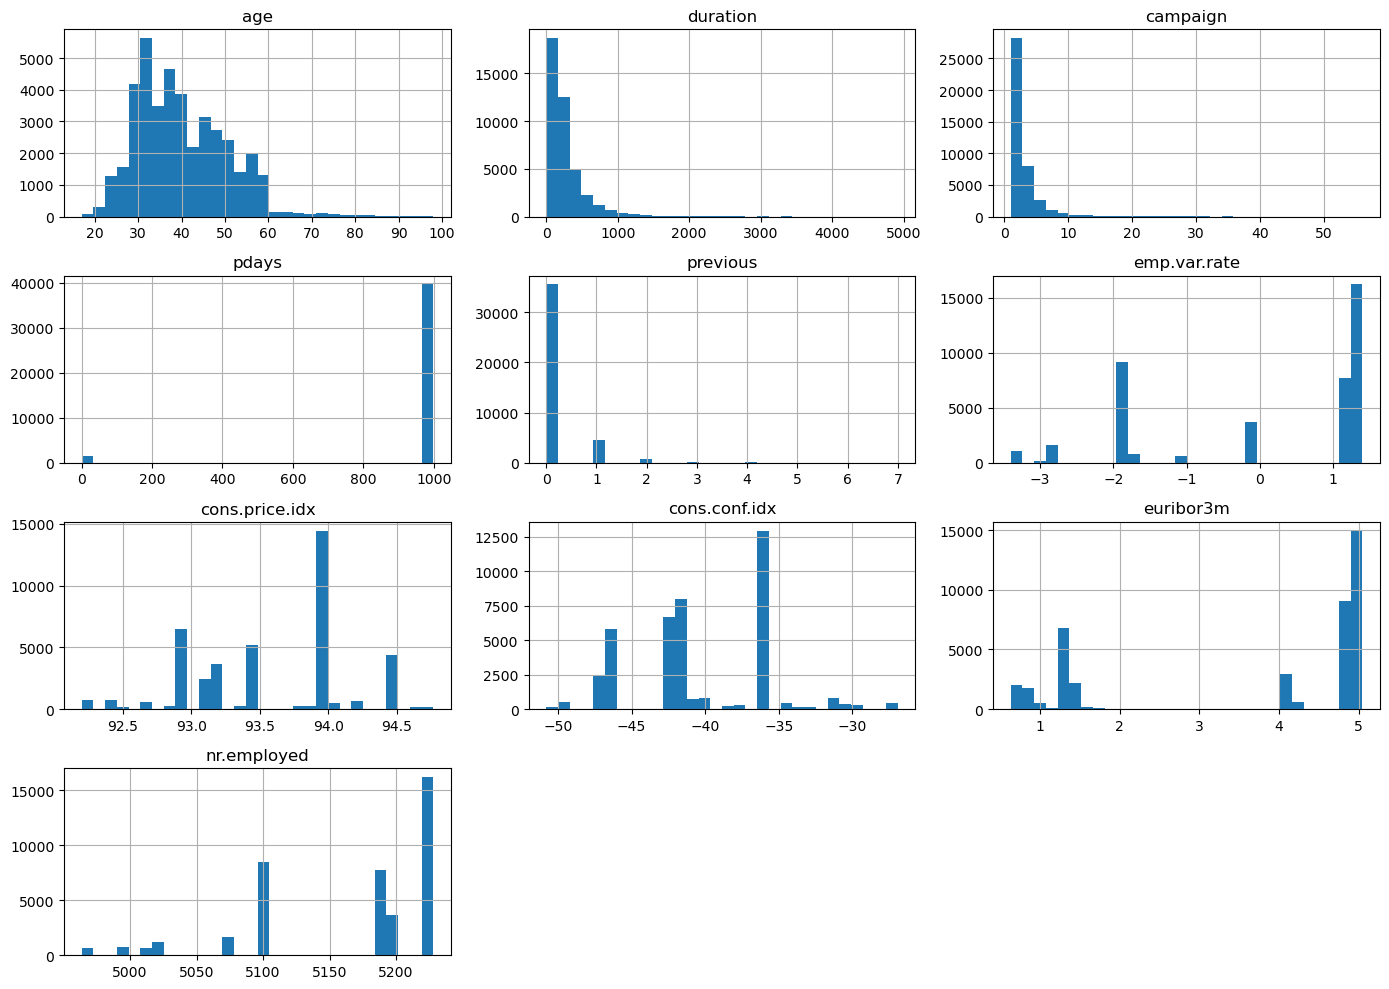

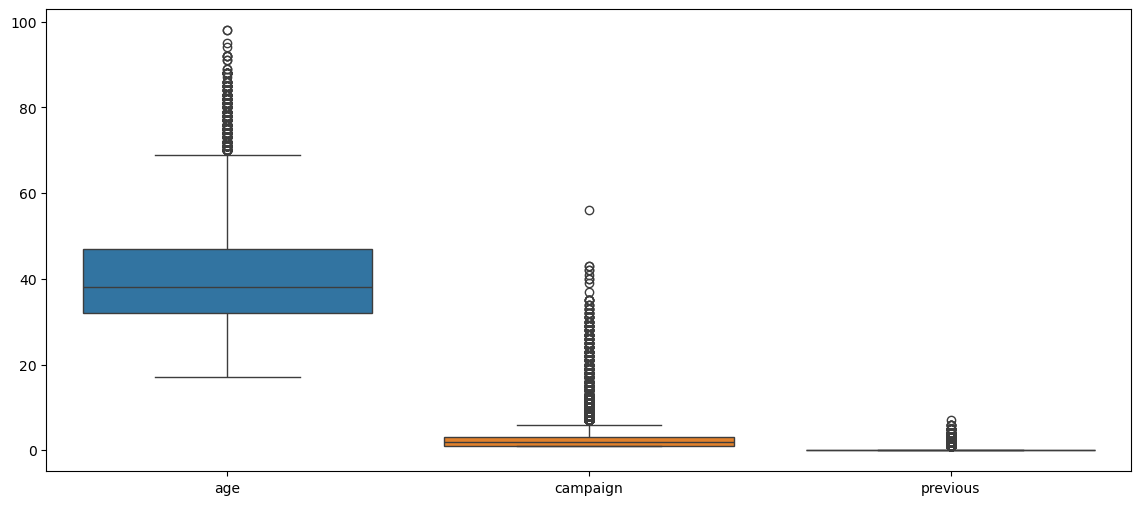

In [6]:
num_cols=df.select_dtypes(include=np.number).columns.tolist()
df[num_cols].hist(figsize=(14,10),bins=30)
plt.tight_layout()
plt.show()
plt.figure(figsize=(14,6))
sns.boxplot(data=df[['age','campaign','previous']])
plt.show()

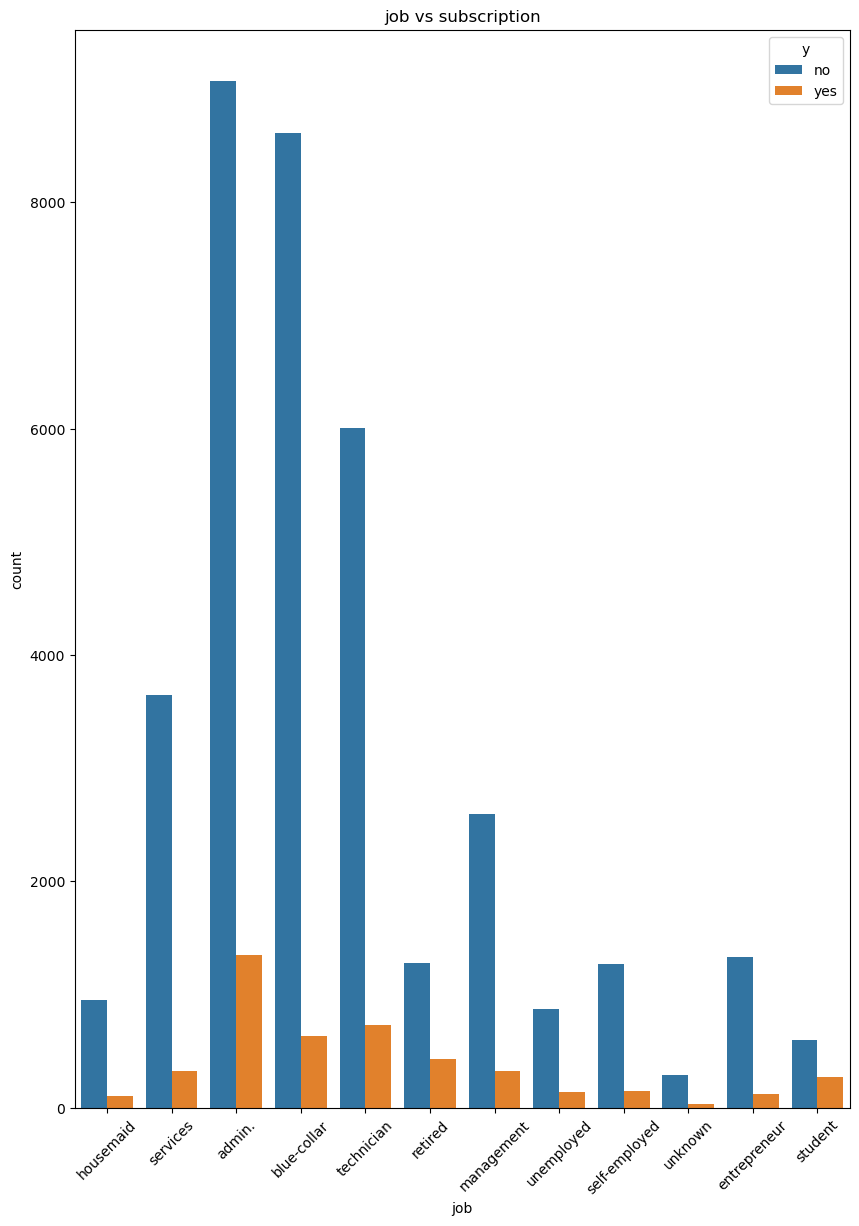

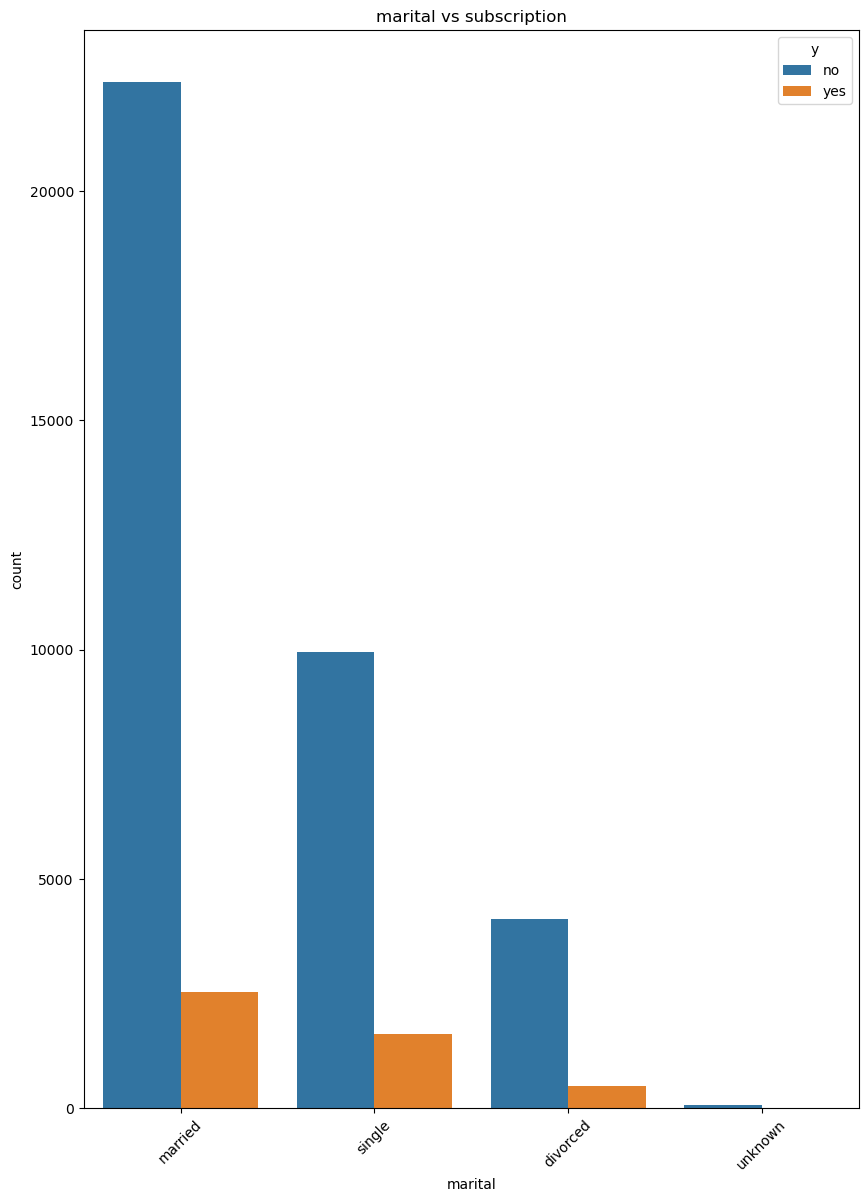

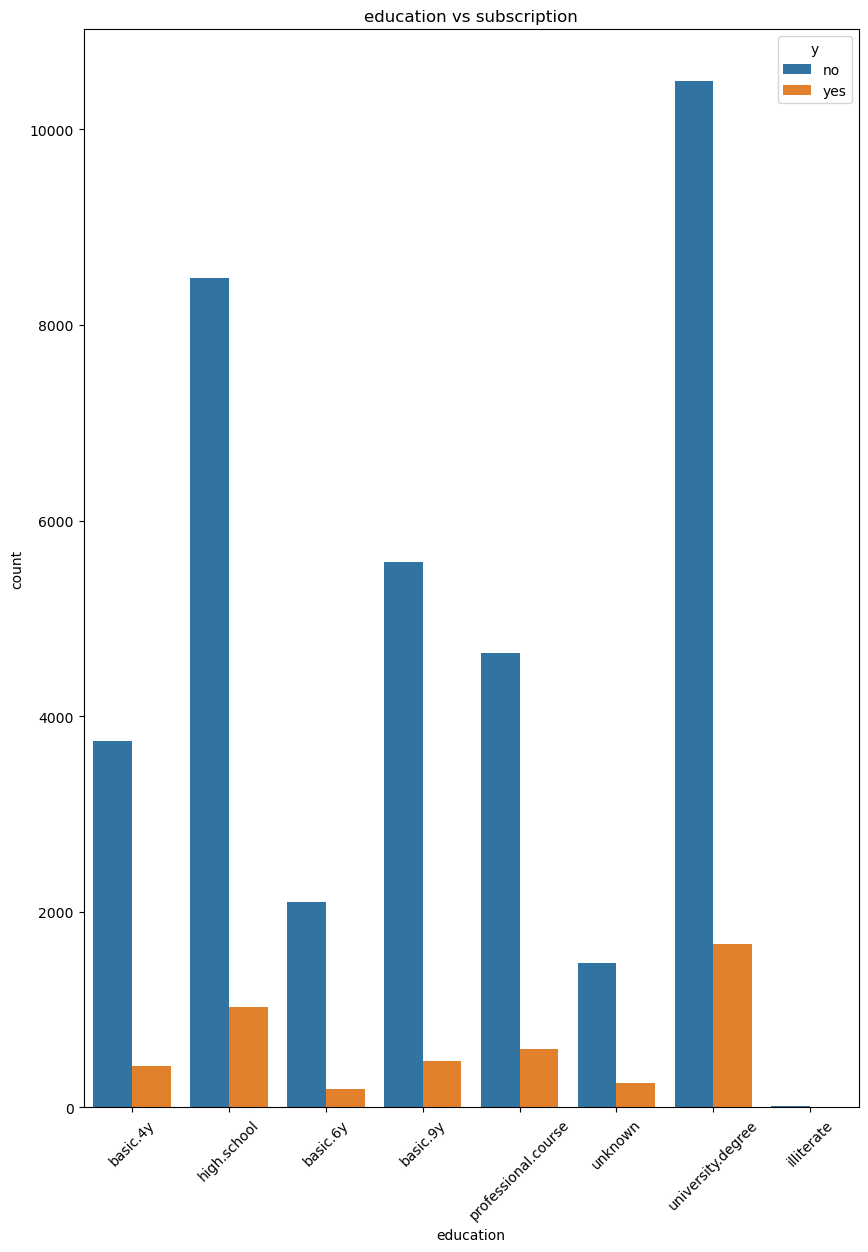

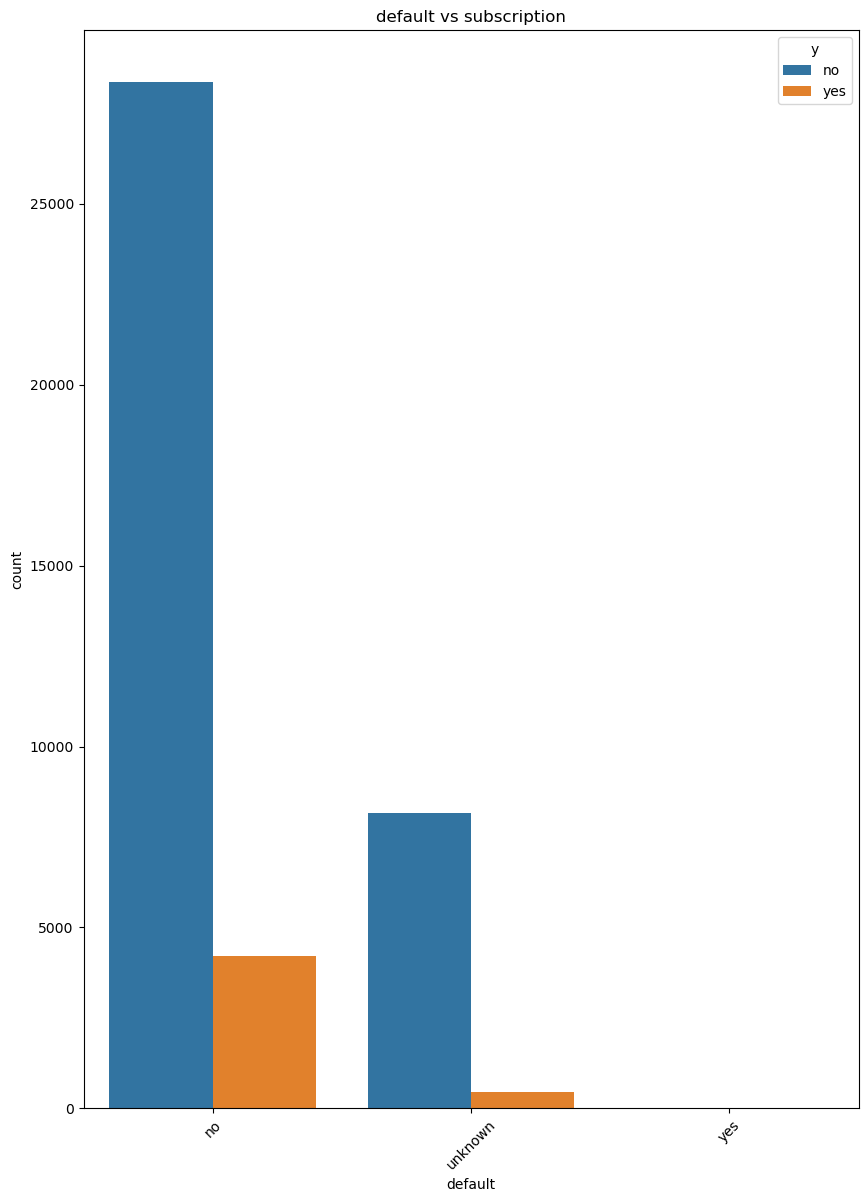

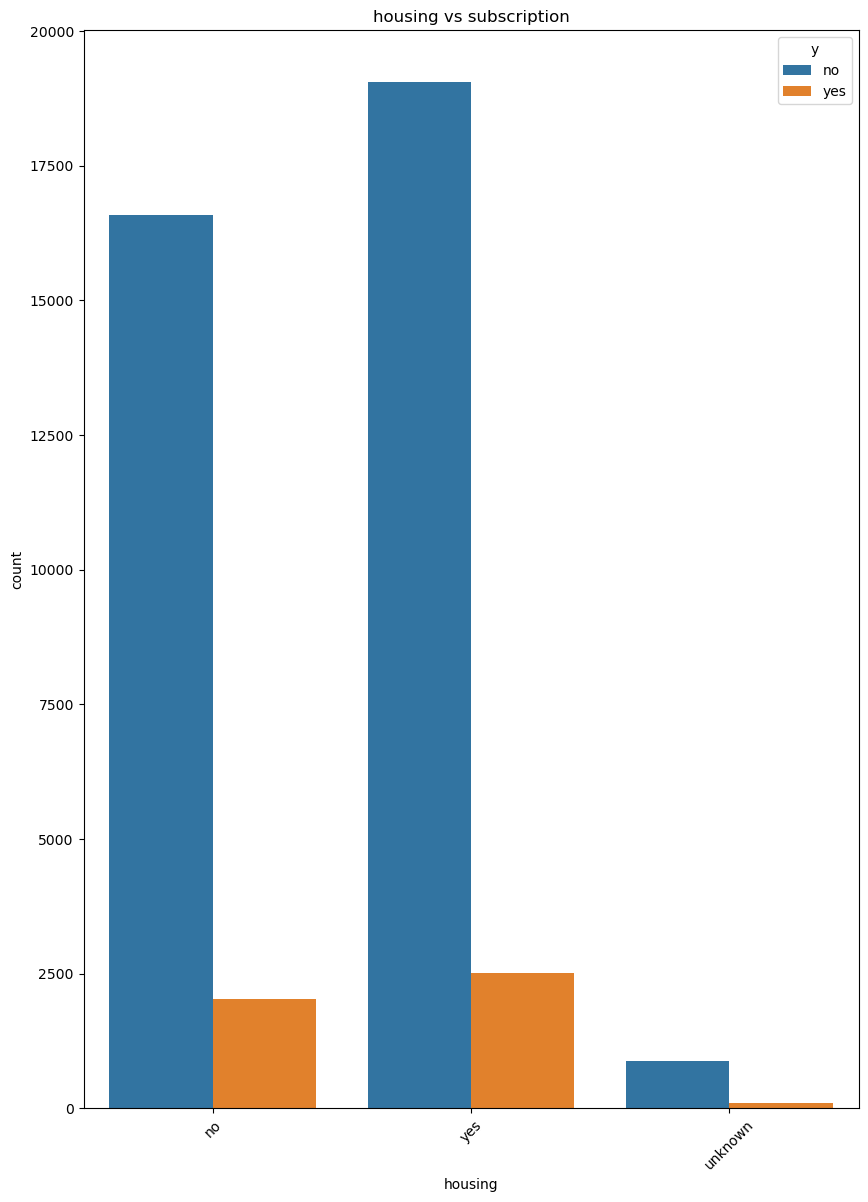

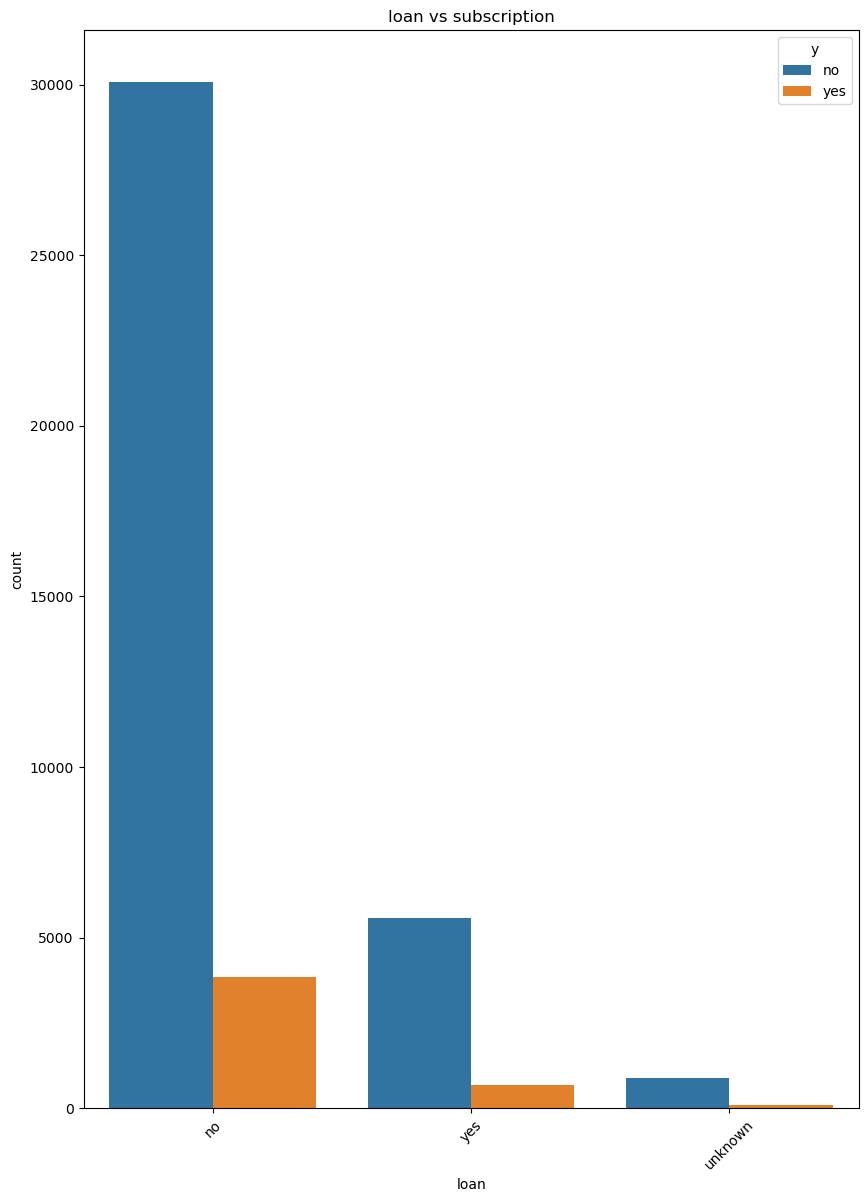

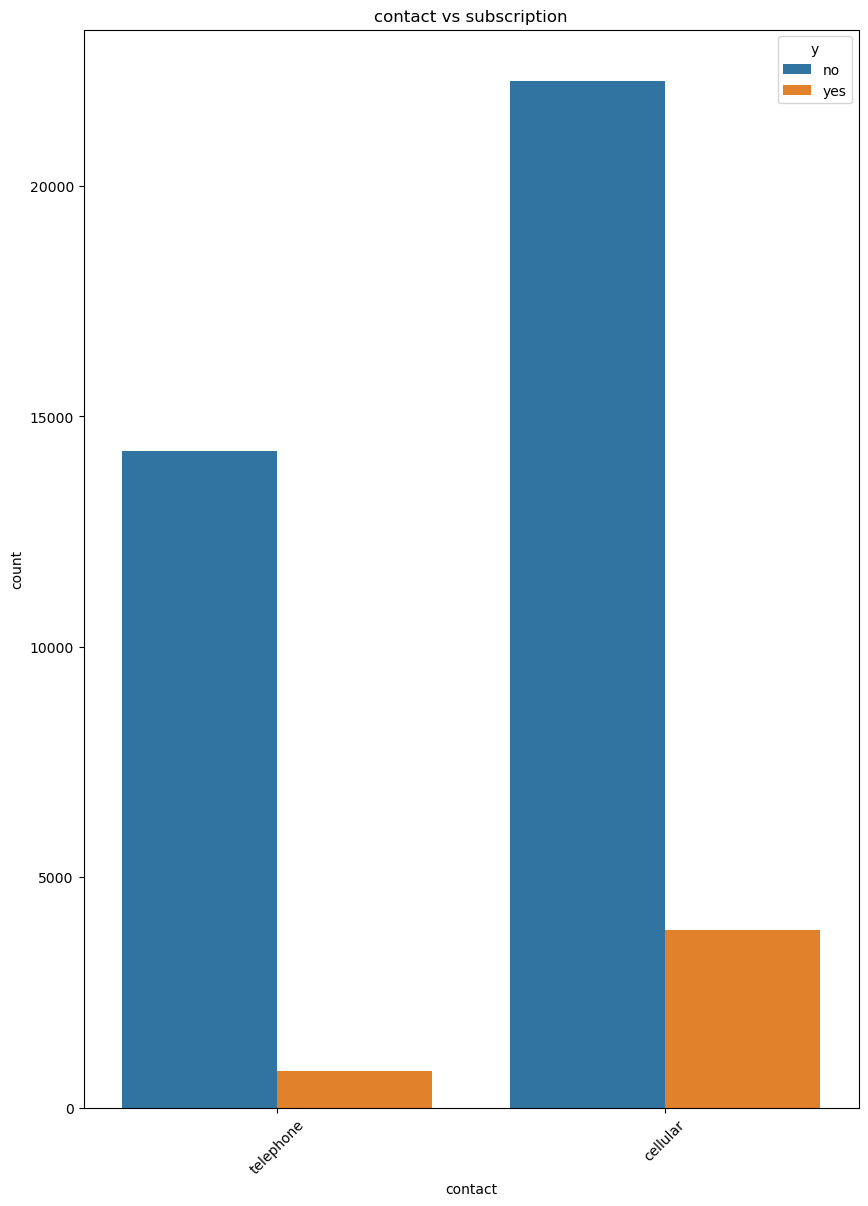

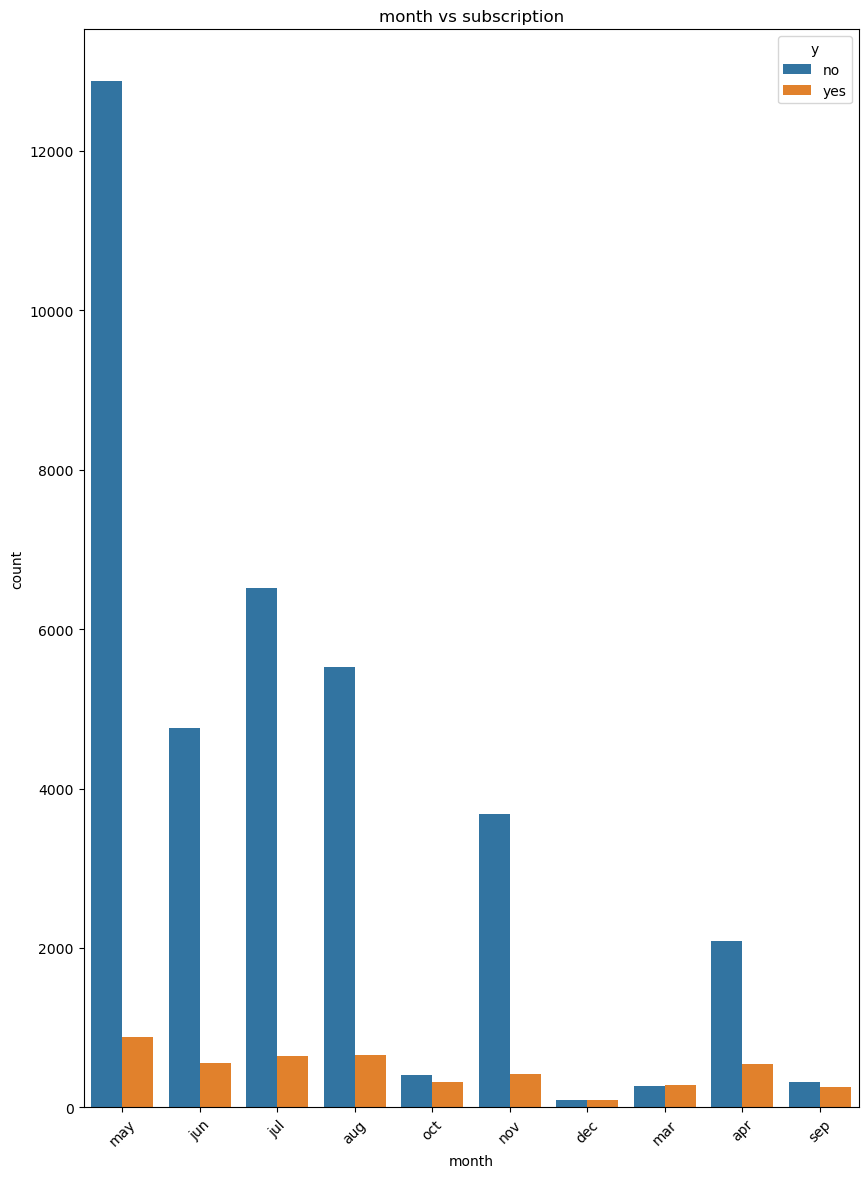

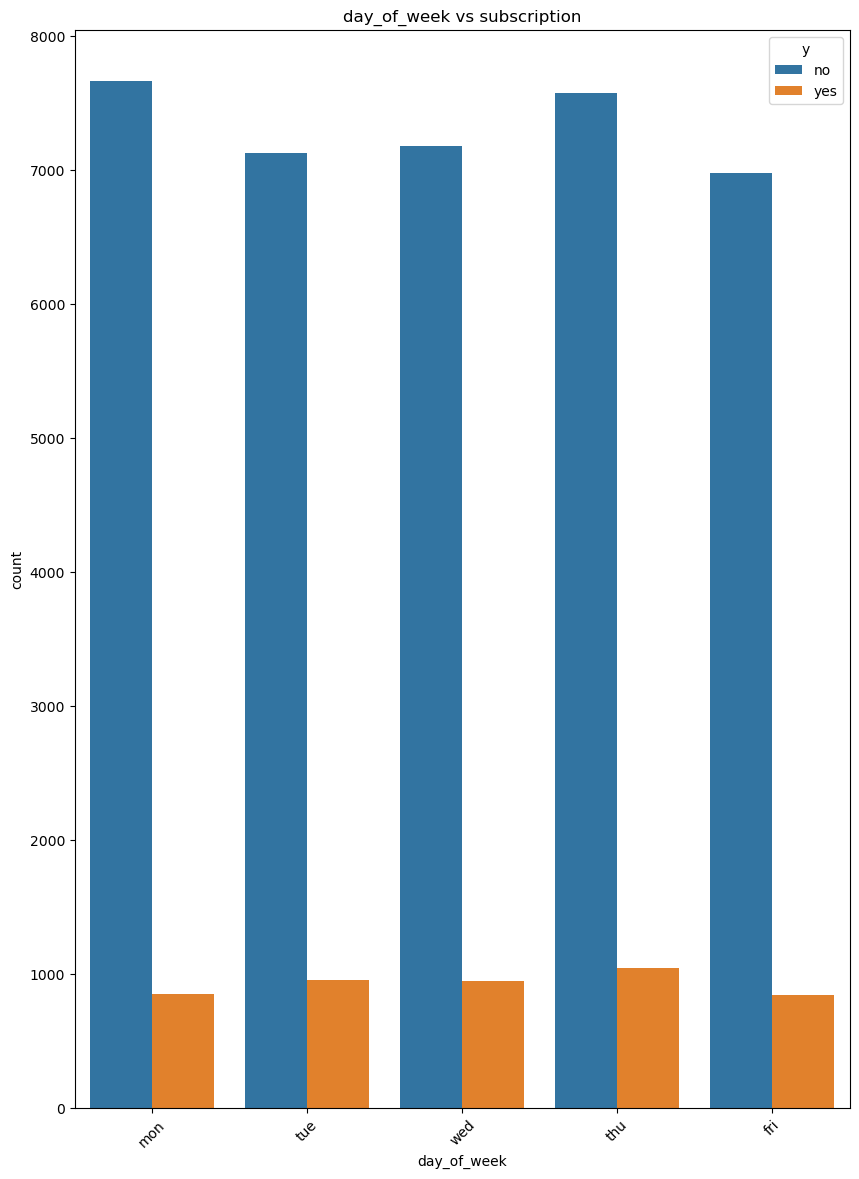

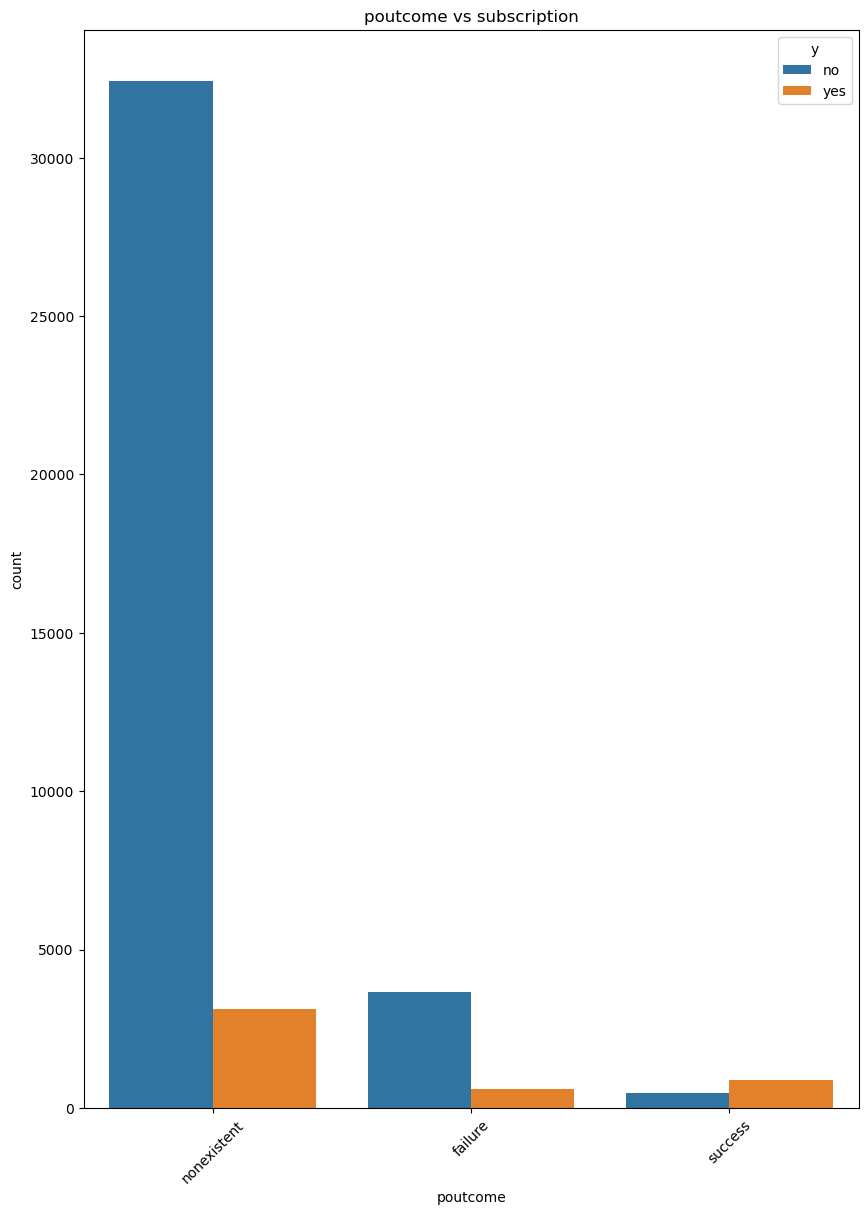

In [7]:
cat_cols=df.select_dtypes(include='object').columns.drop('y')
for col in cat_cols:
    plt.figure(figsize=(10,14))
    sns.countplot(x=col,hue='y',data=df)
    plt.xticks(rotation=45)
    plt.title(f'{col} vs subscription')
    plt.show()

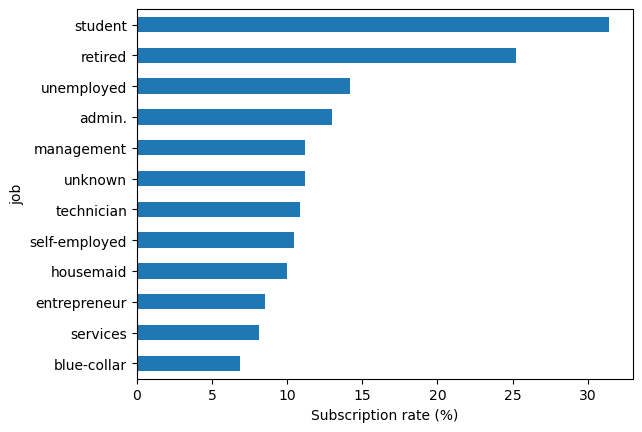

In [8]:
(df.groupby('job')['y'].apply(lambda s:(s=='yes').mean()) *100).sort_values().plot(kind='barh')
plt.xlabel('Subscription rate (%)')
plt.show()

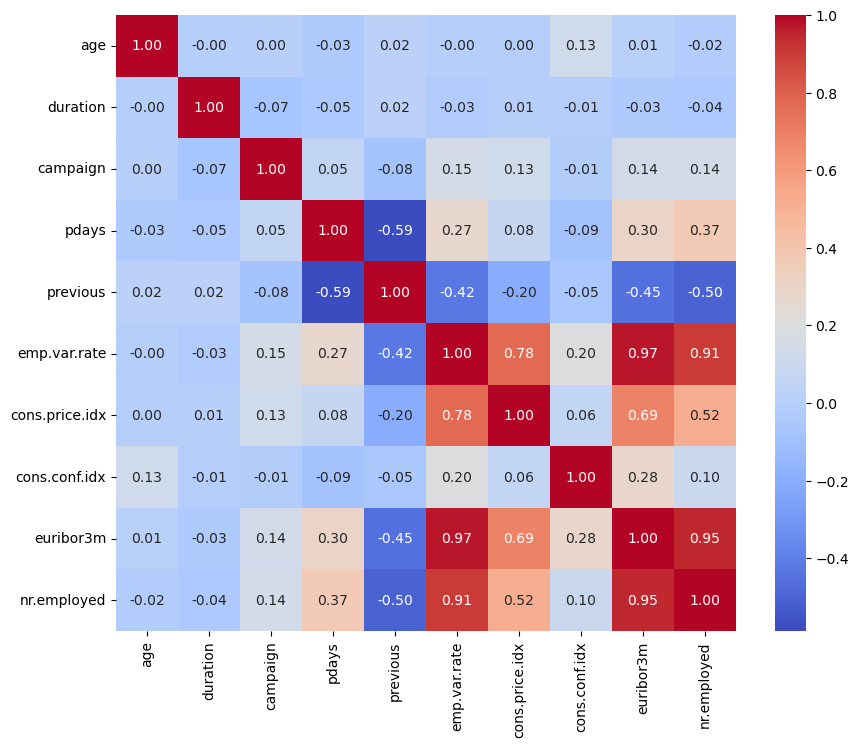

In [9]:
plt.figure(figsize=(10,8))
sns.heatmap(df[num_cols].corr(),annot=True, cmap='coolwarm', fmt='.2f')
plt.show()

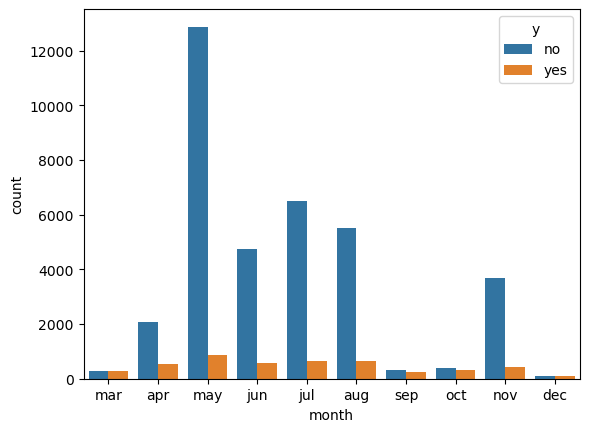

In [10]:
order=['mar','apr','may','jun','jul','aug','sep','oct','nov','dec']
sns.countplot(x='month',hue='y',data=df,order=order)
plt.show()

In [11]:
df=df.drop('duration',axis=1)

In [12]:
 for col in ['job','marital','education','default','housing','loan']:
     print(col, (df[col]=='unknown').mean().round(3))

job 0.008
marital 0.002
education 0.042
default 0.209
housing 0.024
loan 0.024


In [26]:
df['previously_contacted']=(df['pdays']!=999).astype(int)
df['pdays'] = df['pdays'].replace(999, 0)

In [14]:
df['y']=df['y'].map({'yes':1,'no':0})

In [15]:
df=pd.get_dummies(df,drop_first=True)

In [16]:
from sklearn.model_selection import train_test_split 
X=df.drop('y',axis=1)
y=df['y']
X_train,X_test,y_train,y_test=train_test_split(
    X,y,test_size=0.2,random_state=42,stratify=y
)

In [17]:
from sklearn.preprocessing import StandardScaler

scaler=StandardScaler()
X_train_sc=scaler.fit_transform(X_train)
X_test_sc=scaler.transform(X_test)

In [18]:
from imblearn.over_sampling import SMOTE
smote=SMOTE(random_state=42)
X_train_bal,y_train_bal=smote.fit_resample(X_train_sc,y_train)
print(y_train_bal.value_counts())

y
0    29229
1    29229
Name: count, dtype: int64


In [19]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import(accuracy_score,precision_score,recall_score,
                            f1_score,roc_auc_score)
models={
    'Logistic Regression':LogisticRegression(max_iter=1000),
    'Decision Tree':DecisionTreeClassifier(max_depth=6, random_state=42),
    'Random Forest':RandomForestClassifier(n_estimators=200,random_state=42,n_jobs=-1),
    'Gradient Boosting':GradientBoostingClassifier(random_state=42),
    'KNN':KNeighborsClassifier(n_neighbors=7)
}
results=[]
for name, model in models.items():
    model.fit(X_train_bal,y_train_bal)
    pred=model.predict(X_test_sc)
    proba=model.predict_proba(X_test_sc)[:,1]
    results.append({
    'Model':name,
    'Accuracy':accuracy_score(y_test,pred),
    'Precision':precision_score(y_test,pred),
    'Recall':recall_score(y_test,pred),
    'F1':f1_score(y_test,pred),
    'ROC-AUC':roc_auc_score(y_test,proba)
})
results_df=pd.DataFrame(results).sort_values('ROC-AUC',ascending=False)
results_df

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
3,Gradient Boosting,0.890481,0.516373,0.441810,0.476190,0.802241
0,Logistic Regression,0.820908,0.345393,0.658405,0.453096,0.798280
1,Decision Tree,0.882103,0.480257,0.563578,0.518592,0.780750
2,Random Forest,0.887688,0.502256,0.359914,0.419335,0.779002
4,KNN,0.739072,0.247205,0.643319,0.357164,0.736867


In [20]:
from sklearn.model_selection import GridSearchCV
params={'n_estimators':[100,200],'max_depth':[10,20,None],'min_samples_split':[2,5]}
grid=GridSearchCV(RandomForestClassifier(random_state=42,n_jobs=1),
                 params,cv=3,scoring='roc_auc')
grid.fit(X_train_bal,y_train_bal)
print(grid.best_params_,grid.best_score_)
best_model=grid.best_estimator_

{'max_depth': None, 'min_samples_split': 2, 'n_estimators': 200} 0.9859702524857008


              precision    recall  f1-score   support

           0       0.92      0.95      0.94      7308
           1       0.50      0.36      0.42       928

    accuracy                           0.89      8236
   macro avg       0.71      0.66      0.68      8236
weighted avg       0.87      0.89      0.88      8236



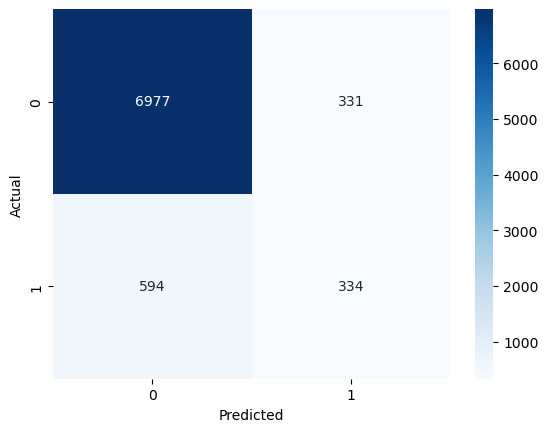

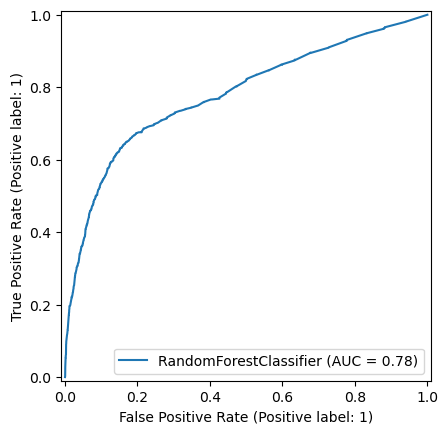

In [21]:
from sklearn.metrics import classification_report, confusion_matrix,RocCurveDisplay
pred = best_model.predict(X_test_sc)
print(classification_report(y_test,pred))
sns.heatmap(confusion_matrix(y_test,pred),annot=True,fmt='d',cmap='Blues')
plt.xlabel('Predicted');plt.ylabel('Actual')
plt.show()
RocCurveDisplay.from_estimator(best_model,X_test_sc,y_test)
plt.show()

In [24]:
from sklearn.metrics import roc_auc_score
print("Tuned RF test ROC-AUC:", roc_auc_score(y_test, best_model.predict_proba(X_test_sc)[:, 1]))

Tuned RF test ROC-AUC: 0.7790037016590228


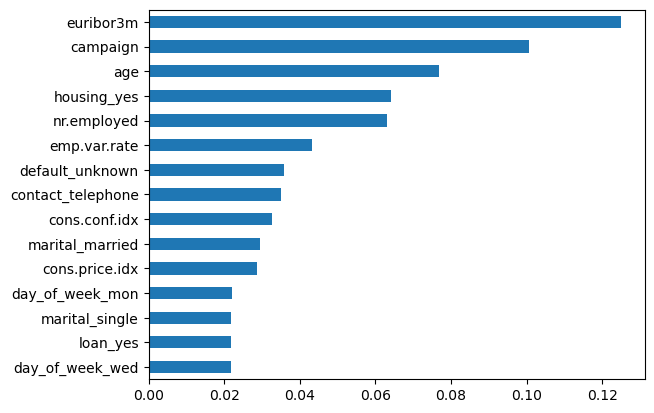

In [25]:
imp=pd.Series(best_model.feature_importances_,index=X.columns).sort_values(ascending=False)
imp.head(15).plot(kind='barh')
plt.gca().invert_yaxis()
plt.show()

Data analysis report:-
1.   Only about 11% of customers said yes, so the data is imbalanced.
2.   Students and retired people subscribe the most.
3.   The euribor3m, nr.employed and emp.var.rate columns are highly correlated.
4.   Customers who said yes in a previous campaign subscribe at about 65%, compared with about 9% for first-time contacts.
5.   Cellular contact converts at about 15%, while telephone converts at about 5%.
6.   May has by far the most calls but converts only about 6%. March, September, October and December convert at about 44-50% on very few calls.
7.   Customers aged 24 or under, and over 60, subscribe much more often than those aged 25-60.
8.   Customers whose `default` status is unknown convert at only about 5%.

Suggestions for the marketing team:-
1.   Call customers who said yes in a past campaign first.
2.   Use cellular contact instead of landline.
3.   Don't call the same customer too many times.
4.   Run more campaigns in March, September, October and December, and fewer in May.
5.   Focus on students, retired people and customers aged 24 or under or over 60.
6.   Cap repeat calls (for example 3-4 attempts per customer), because the "yes" customers needed fewer contacts on average.
7.   Time deposit campaigns for when interest rates (euribor) are low, because they are the model's top predictors.
8.   Use the model's probability to rank customers and call the most likely ones first.

## Model Comparison Report

| Model | Accuracy | Precision | Recall | F1 | ROC-AUC |
|---|---|---|---|---|---|
| Gradient Boosting | 0.890 | 0.516 | 0.442 | 0.476 | 0.802 |
| Logistic Regression | 0.821 | 0.345 | 0.658 | 0.453 | 0.798 |
| Decision Tree | 0.882 | 0.480 | 0.564 | 0.519 | 0.781 |
| Random Forest | 0.888 | 0.502 | 0.360 | 0.419 | 0.779 |
| KNN | 0.739 | 0.247 | 0.643 | 0.357 | 0.737 |

Five models were trained on SMOTE-balanced data and tested on a hidden 20% test set. Because only about 11% of customers subscribe, accuracy alone is misleading, so ROC-AUC, recall and F1 were also used.

- Gradient Boosting has the best ROC-AUC (0.802), the best accuracy (0.890) and the best precision among the top models.
- Logistic Regression is almost as good on ROC-AUC (0.798) and finds the most buyers (recall 0.658), but it makes many more wasted calls (precision 0.345).
- KNN is the weakest model on ROC-AUC (0.737) and precision.
- The tuned Random Forest (GridSearchCV) scored 0.779 ROC-AUC on the test set. It did not beat Gradient Boosting, and it finds only 36% of buyers.

**Recommended model for production: Gradient Boosting**, because it ranks customers best and balances accuracy with precision. If the bank cares more about reaching as many buyers as possible than about wasted calls, Logistic Regression is a good alternative because it is simple and explainable.

## Report on Challenges Faced

| Challenge | Technique used | Reason |
|---|---|---|
| `duration` is only known after the call | Dropped the column | It leaks the answer, so a model using it would be unusable before calling |
| Imbalanced target (about 11% yes) | SMOTE on the training data, and checking recall, F1 and ROC-AUC | Accuracy is misleading, and SMOTE balances the classes |
| `unknown` values in job, marital, education, default, housing and loan | Kept them as their own category | There are no NaN values, `unknown` can carry information, and imputing would add guesswork |
| `pdays` = 999 means "never contacted" | Created a `previously_contacted` flag and replaced 999 with 0 | 999 is a code, not a real number of days |
| Duplicate rows (12) | Removed them | Avoids double counting |
| Highly correlated columns (`emp.var.rate`, `euribor3m`, `nr.employed`) | Used tree-based models and compared with Logistic Regression | Trees are not affected by correlated inputs |
| Different scales between columns | StandardScaler | Needed for Logistic Regression and KNN |
| Text categories | One-hot encoding | Models need numbers |
| Grid search score looked too high (0.986) | Judged models on the hidden test set instead | SMOTE was applied before cross-validation, so the validation folds contained synthetic copies of training customers, which inflated the score. The real test ROC-AUC was 0.779 |